# 00 — Gymnasium basics, visually

<div><span style="display:inline-block;background:#334155;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ENVIRONMENT</span><span style="display:inline-block;background:#17BECF;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">OBSERVATION</span><span style="display:inline-block;background:#0F766E;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">POLICY</span><span style="display:inline-block;background:#F58518;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ACTION</span><span style="display:inline-block;background:#B279A2;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">TRANSITION</span><span style="display:inline-block;background:#4C78A8;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">STATE</span><span style="display:inline-block;background:#54A24B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">REWARD</span><span style="display:inline-block;background:#5B8FF9;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">S PRIME</span><span style="display:inline-block;background:#E45756;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">LEARNING</span><span style="display:inline-block;background:#ECA82C;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">Q</span><span style="display:inline-block;background:#8B5CF6;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">EPISODE</span></div>

This notebook is the foundation. We use a tiny six-position world so every piece of the RL loop is visible.

**Goal:** by the end, `reset()` and `step()` should feel like ordinary functions, not RL magic.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-000" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">The RL loop</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">WORLD</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-000)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">OBSERVATION</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-000)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POLICY</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-000)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACTION</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-000)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#B279A2" stroke="#B279A2" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">WORLD CHANGES</text>
</svg>
</div>


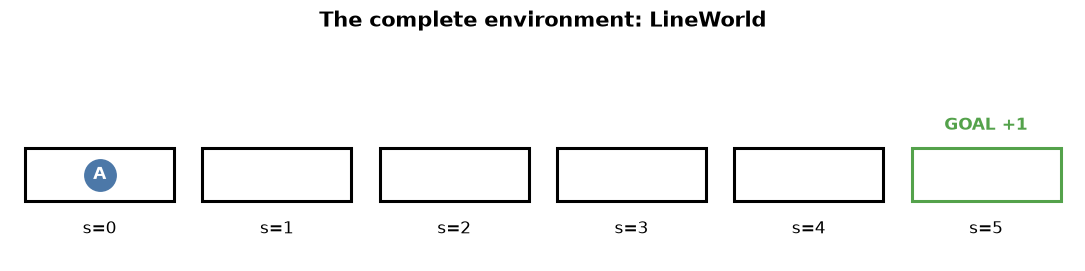

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces

repo = Path.cwd()
if repo.name == "notebooks":
    repo = repo.parent
sys.path.insert(0, str(repo))
from visuals import gridworld, pipeline, qtable_heatmap, COLORS

class LineWorld(gym.Env):
    def __init__(self):
        self.action_space = spaces.Discrete(2)      # 0 LEFT, 1 RIGHT
        self.observation_space = spaces.Discrete(6)
        self.position = 0
        self.steps = 0

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.position = 0
        self.steps = 0
        return self.position, {}

    def step(self, action):
        self.steps += 1
        old = self.position
        if action == 0:
            self.position = max(0, self.position - 1)
        else:
            self.position = min(5, self.position + 1)

        terminated = self.position == 5
        truncated = self.steps >= 30
        reward = 1.0 if terminated else -0.02
        info = {"old_position": old}
        return self.position, reward, terminated, truncated, info

env = LineWorld()
fig = gridworld(position=0, goal=5, title="The complete environment: LineWorld")
plt.show()

<div style="border-left:10px solid #334155;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#334155">ENVIRONMENT</div><div style="font-size:21px;font-weight:800;margin-top:4px">1. What <code>reset()</code> actually does</div></div>

`reset()` creates a fresh episode. It initializes the environment's internal state and returns the first observation.

The environment already has a true state: here, the agent is at position 0.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-002" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">`reset()`</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">reset()</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-002)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">TRUE STATE = 0</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-002)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">OBSERVATION = 0</text>
</svg>
</div>


Returned observation: 0
Internal environment position: 0


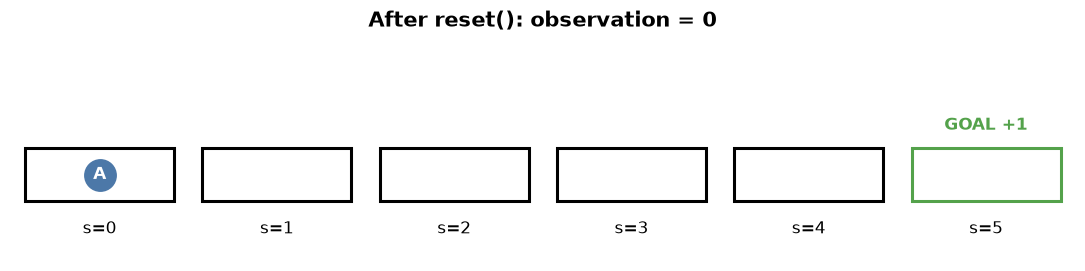

In [2]:
obs, info = env.reset(seed=1)
print("Returned observation:", obs)
print("Internal environment position:", env.position)

fig = gridworld(position=env.position, goal=5, title=f"After reset(): observation = {obs}")
plt.show()

<div style="border-left:10px solid #B279A2;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#B279A2">TRANSITION</div><div style="font-size:21px;font-weight:800;margin-top:4px">2. One <code>step(action)</code></div></div>

An **action** is what the policy chooses.

Then the **environment** applies its transition rule and returns:

`next_observation, reward, terminated, truncated, info`.

RIGHT is action `1`.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-004" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">`step(1)`</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">STATE 0</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-004)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACTION: RIGHT</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-004)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#B279A2" stroke="#B279A2" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">TRANSITION</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-004)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">STATE 1</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-004)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">REWARD -0.02</text>
</svg>
</div>


Before: 0
Action: RIGHT
After: 1
Reward: -0.02
Terminated: False


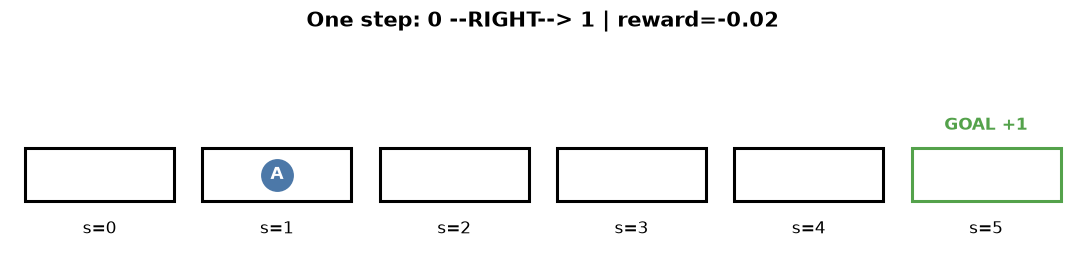

In [3]:
before = env.position
action = 1
obs, reward, terminated, truncated, info = env.step(action)
after = env.position

print("Before:", before)
print("Action:", "RIGHT")
print("After:", after)
print("Reward:", reward)
print("Terminated:", terminated)

fig = gridworld(position=after, goal=5, title=f"One step: {before} --RIGHT--> {after} | reward={reward}")
plt.show()

<div style="border-left:10px solid #0F766E;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#0F766E">POLICY</div><div style="font-size:21px;font-weight:800;margin-top:4px">3. Policy = the chooser</div></div>

A policy is simply whatever chooses the next action from the information it has.

It can be you, an `if` statement, a table, a neural network, or an LLM harness.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-006" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Policy means &#x27;chooser&#x27;</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">OBSERVATION</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-006)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POLICY π</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-006)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACTION</text>
</svg>
</div>


Actions: ['LEFT', 'LEFT', 'RIGHT', 'LEFT', 'RIGHT', 'RIGHT', 'LEFT', 'RIGHT', 'LEFT', 'RIGHT', 'RIGHT', 'RIGHT']


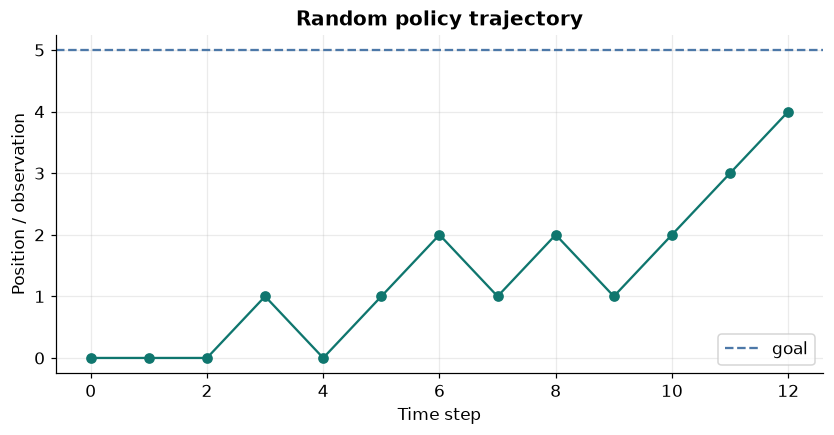

In [4]:
def random_policy(obs):
    return env.action_space.sample()

obs, _ = env.reset(seed=3)
positions = [obs]
actions = []

for t in range(12):
    a = random_policy(obs)
    actions.append(a)
    obs, reward, term, trunc, _ = env.step(a)
    positions.append(obs)
    if term or trunc:
        break

print("Actions:", ["LEFT" if a == 0 else "RIGHT" for a in actions])

plt.figure(figsize=(9,4))
plt.plot(range(len(positions)), positions, marker="o", color=COLORS["POLICY"])
plt.axhline(5, linestyle="--", label="goal")
plt.xlabel("Time step")
plt.ylabel("Position / observation")
plt.title("Random policy trajectory")
plt.legend()
plt.show()

<div style="border-left:10px solid #54A24B;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#54A24B">REWARD</div><div style="font-size:21px;font-weight:800;margin-top:4px">4. Reward does not move the world</div></div>

The transition rule moves the world. Reward is a numeric evaluation signal returned **after** the action.

Here, wandering costs `-0.02` each step and reaching the goal gives `+1`.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-008" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Reward is feedback</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACTION</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-008)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#5B8FF9" stroke="#5B8FF9" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">NEXT STATE</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-008)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">REWARD</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-008)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#E45756" stroke="#E45756" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">LEARNING UPDATE</text>
</svg>
</div>


Return (sum of rewards): 0.92


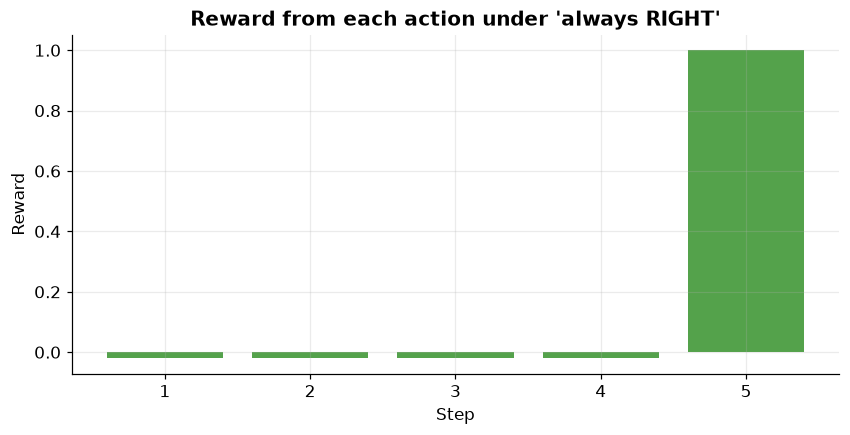

In [5]:
def always_right(obs):
    return 1

obs, _ = env.reset()
positions = [obs]
rewards = []
total = 0

while True:
    a = always_right(obs)
    obs, r, term, trunc, _ = env.step(a)
    positions.append(obs)
    rewards.append(r)
    total += r
    if term or trunc:
        break

print("Return (sum of rewards):", total)

plt.figure(figsize=(9,4))
plt.bar(range(1, len(rewards)+1), rewards, color=COLORS["REWARD"])
plt.xlabel("Step")
plt.ylabel("Reward")
plt.title("Reward from each action under 'always RIGHT'")
plt.show()

<div style="border-left:10px solid #ECA82C;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#ECA82C">Q</div><div style="font-size:21px;font-weight:800;margin-top:4px">5. Q-learning = change your opinion of actions from experience</div></div>

`Q(s,a)` stores an estimate of long-term value for taking action `a` in state `s`.

Initially every Q-value is zero. Experience changes the table.

> **If this feels like a jump:** this section squeezes the whole micro-course into one cell. `00_01` (Q-table) → `00_02` (step, s′, reward) → `00_03` (γ, Bellman) → `00_04` (α, TD error) → `00_05` (ε) → `00_06` (one episode) → `00_07` (training) take it one line at a time.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-0010" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Q-learning update</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">STATE s</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0010)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACTION a</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0010)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">REWARD r</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0010)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#5B8FF9" stroke="#5B8FF9" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">NEXT STATE s′</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0010)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#ECA82C" stroke="#ECA82C" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">UPDATE Q(s,a)</text>
</svg>
</div>


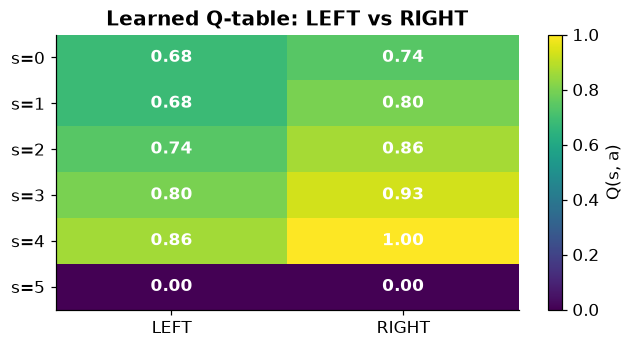

In [6]:
Q = np.zeros((6,2))
alpha = 0.2
gamma = 0.95
epsilon = 0.25
episode_returns = []

for episode in range(300):
    obs, _ = env.reset()
    total = 0.0
    while True:
        if np.random.rand() < epsilon:
            action = env.action_space.sample()
        else:
            action = int(np.argmax(Q[obs]))

        next_obs, reward, term, trunc, _ = env.step(action)
        future = 0.0 if term else np.max(Q[next_obs])
        Q[obs, action] += alpha * (reward + gamma*future - Q[obs, action])

        total += reward
        obs = next_obs
        if term or trunc:
            break
    episode_returns.append(total)

fig = qtable_heatmap(Q, title="Learned Q-table: LEFT vs RIGHT")
plt.xticks([0,1], ["LEFT","RIGHT"])
plt.show()

<div style="border-left:10px solid #E45756;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#E45756">LEARNING</div><div style="font-size:21px;font-weight:800;margin-top:4px">6. What learning changed</div></div>

The environment did **not** learn. LineWorld's rules stayed fixed.

The **policy-producing Q-values** changed, so later the chooser prefers actions that historically led to better return.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-0012" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">What learned?</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">FIXED ENVIRONMENT</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0012)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#8B5CF6" stroke="#8B5CF6" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">EXPERIENCE</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0012)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#ECA82C" stroke="#ECA82C" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">Q VALUES CHANGE</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0012)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POLICY CHANGES</text>
</svg>
</div>


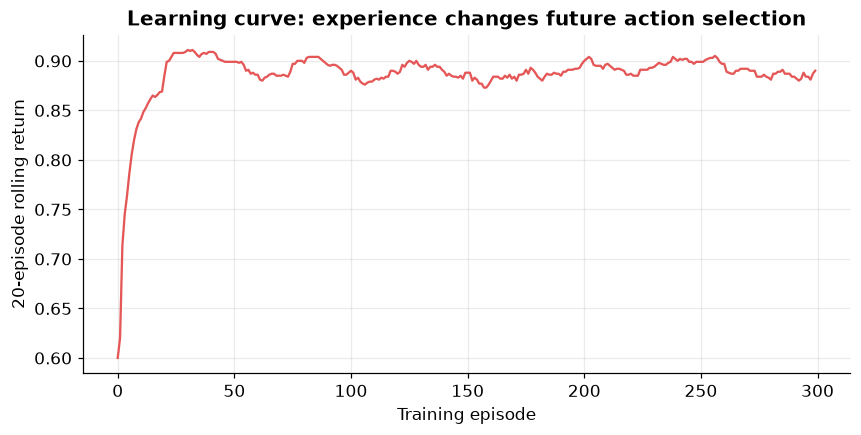

Greedy learned policy:
state 0 -> RIGHT
state 1 -> RIGHT
state 2 -> RIGHT
state 3 -> RIGHT
state 4 -> RIGHT


In [7]:
plt.figure(figsize=(9,4))
plt.plot(pd.Series(episode_returns).rolling(20, min_periods=1).mean(), color=COLORS["LEARNING"])
plt.xlabel("Training episode")
plt.ylabel("20-episode rolling return")
plt.title("Learning curve: experience changes future action selection")
plt.show()

print("Greedy learned policy:")
for s in range(5):
    print(f"state {s} ->", "RIGHT" if np.argmax(Q[s]) == 1 else "LEFT")

<div style="border-left:10px solid #64748B;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#64748B">KEY IDEA</div><div style="font-size:21px;font-weight:800;margin-top:4px">Memorize this before moving on</div></div>

**Environment reacts. Policy chooses. Reward grades. Learning changes future choosing.**

Next, Toy Pong keeps the same loop but makes the state multidimensional.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-0014" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">One loop, many problems</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ENVIRONMENT</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0014)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">STATE/OBS</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0014)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POLICY</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0014)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACTION</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0014)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">REWARD</text>
</svg>
</div>
